In [16]:
import numpy as np
from matplotlib import pyplot as plt
import imutils
import matplotlib.cm as cm
import ipywidgets as widgets
from IPython.display import display, clear_output
from skimage import data
import glob
import open3d as o3d
import copy
from sklearn.linear_model import LinearRegression
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans, k_means
from sklearn import linear_model
from IPython.display import Image, display
from math import *
from scipy import ndimage, signal
import sklearn as sk
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
import pandas as pd
from sklearn.decomposition import PCA
import math
import time
import datetime as dt
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml
import ssl
from sklearn.datasets import fetch_lfw_people
from sklearn.neighbors import KNeighborsClassifier
from tqdm import tqdm
from sklearn.model_selection import LeaveOneOut, KFold, StratifiedKFold
import cv2
from numpy.linalg import inv, pinv

# Calibrate Camera

In [17]:
folder = '../0_calib/'
img_L = glob.glob(folder + 'left/*.png')
img_R = glob.glob(folder + 'right/*.png')
assert img_L
assert img_R

## Left

In [18]:
nb_vertical = 5
nb_horizontal = 7

# prepare object points, like (0,0,0), (1,0,0), (2,0,0) ....,(6,5,0)
objp = np.zeros((nb_horizontal*nb_vertical,3), np.float32)
objp[:,:2] = np.mgrid[0:nb_vertical,0:nb_horizontal].T.reshape(-1,2)

# Arrays to store object points and image points from all the images.
objpoints = [] # 3d point in real world space
imgpoints_L = [] # 2d points in image plane.

for fname in img_L:
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(gray, (nb_vertical, nb_horizontal))

    # If found, add object points, image points (after refining them)
    if ret == True:
        objpoints.append(objp)
        imgpoints_L.append(corners)

        # # Draw and display the corners
        img = cv2.drawChessboardCorners(img, (nb_vertical,nb_horizontal), corners,ret)
        cv2.imshow('img',img)
        cv2.waitKey(50)

cv2.destroyAllWindows()

ret_L, mtx_L, dist_L, rvecs_L, tvecs_L = cv2.calibrateCamera(objpoints, imgpoints_L, gray.shape[::-1], None, None)

# undistort all images
imgs_L = []
img_Lu = []

for i, fname in enumerate(img_L):
    img = cv2.imread(fname)
    imgs_L.append(img)
    h,  w = img.shape[:2]
    newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx_L,dist_L,(w,h),1,(w,h))

    # undistort
    img_Lu.append(cv2.undistort(img, mtx_L, dist_L, None, newcameramtx))


# Right:

In [19]:
# prepare object points, like (0,0,0), (1,0,0), (2,0,0) ....,(6,5,0)
objp = np.zeros((nb_horizontal*nb_vertical,3), np.float32)
objp[:,:2] = np.mgrid[0:nb_vertical,0:nb_horizontal].T.reshape(-1,2)

# Arrays to store object points and image points from all the images.
objpoints = [] # 3d point in real world space
imgpoints_R = [] # 2d points in image plane.

for fname in img_R:
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(gray, (nb_vertical, nb_horizontal))

    # If found, add object points, image points (after refining them)
    if ret == True:
        objpoints.append(objp)

        imgpoints_R.append(corners)

        # Draw and display the corners
        img = cv2.drawChessboardCorners(img, (nb_vertical,nb_horizontal), corners,ret)
        cv2.imshow('img',img)
        cv2.waitKey(50)

cv2.destroyAllWindows()

ret_R, mtx_R, dist_R, rvecs_R, tvecs_R = cv2.calibrateCamera(objpoints, imgpoints_R, gray.shape[::-1], None, None)

# undistort all images
imgs_R = []
img_Ru = []

for i, fname in enumerate(img_R):
    img = cv2.imread(fname)
    imgs_R.append(img)
    h,  w = img.shape[:2]
    newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx_R,dist_R,(w,h),1,(w,h))

    # undistort
    img_Ru.append(cv2.undistort(img, mtx_R, dist_R, None, newcameramtx))


## Stereo calibrate

In [20]:
ret, _, _, _, _, R, T, E, F = cv2.stereoCalibrate(objpoints, imgpoints_L, imgpoints_R, mtx_L, dist_L, mtx_R, dist_R, (w,h), flags=cv2.CALIB_FIX_INTRINSIC)

R1, R2, P1, P2, Q, roi1, roi2 = cv2.stereoRectify(mtx_L, dist_L, mtx_R, dist_R, (w,h), R, T)

In [ ]:
np.savez_compressed(
    "calibration_values.npz",
    ret_R=ret_R,
    mtx_R=mtx_R,
    dist_R=dist_R,
    rvecs_R=np.asarray(rvecs_R),
    tvecs_R=np.asarray(tvecs_R),
    ret_L=ret_L,
    mtx_L=mtx_L,
    dist_L=dist_L,
    rvecs_L=np.asarray(rvecs_L),
    tvecs_L=np.asarray(tvecs_L),
    ret=ret,
    R=R,
    T=T,
    E=E,
    F=F,
    R1=R1,
    R2=R2,
    P1=P1,
    P2=P2,
    Q=Q,
    roi1=np.asarray(roi1),
    roi2=np.asarray(roi2),
)

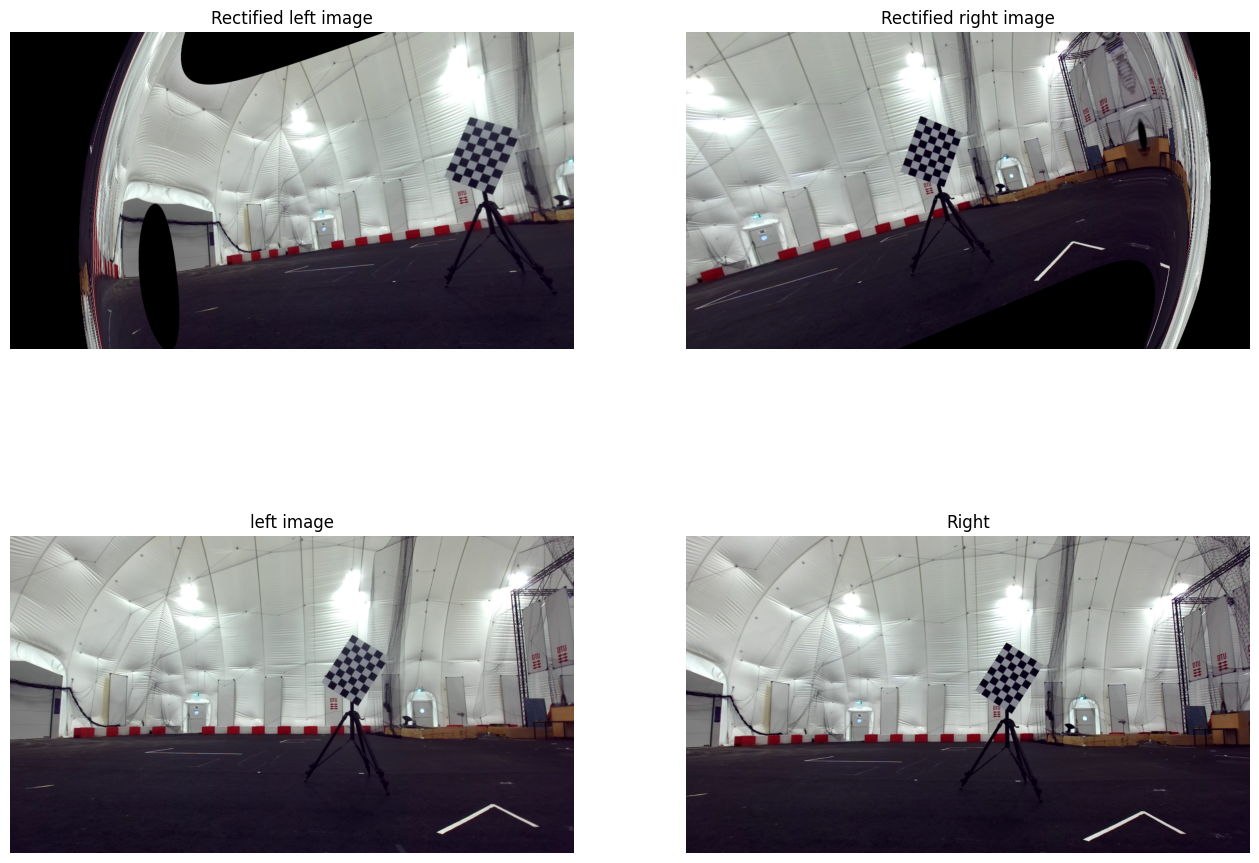

In [21]:
mapLx, mapLy = cv2.initUndistortRectifyMap(mtx_L, dist_L, R1, P1, (w, h), cv2.CV_32FC1)
mapRx, mapRy = cv2.initUndistortRectifyMap(mtx_R, dist_R, R2, P2, (w, h), cv2.CV_32FC1)

# Use corresponding images
left = imgs_L[0]
right = imgs_R[0]

left_rect = cv2.remap(left, mapLx, mapLy, cv2.INTER_LINEAR)
right_rect = cv2.remap(right, mapRx, mapRy, cv2.INTER_LINEAR)

fig, ax = plt.subplots(2, 2, figsize=(16, 12))

ax[0,0].imshow(cv2.cvtColor(left_rect, cv2.COLOR_BGR2RGB))
ax[0,0].set_title("Rectified left image")
ax[0,0].axis("off")

ax[0,1].imshow(cv2.cvtColor(right_rect, cv2.COLOR_BGR2RGB))
ax[0,1].set_title("Rectified right image")
ax[0,1].axis("off")

ax[1,0].imshow(cv2.cvtColor(left, cv2.COLOR_BGR2RGB))
ax[1,0].set_title("left image")
ax[1,0].axis("off")

ax[1,1].imshow(cv2.cvtColor(right, cv2.COLOR_BGR2RGB))
ax[1,1].set_title("Right")
ax[1,1].axis("off")

plt.show()

In [22]:
left_rect = []
right_rect = []
for image in imgs_L:
    left_rect.append(cv2.remap(image, mapLx, mapLy, cv2.INTER_LINEAR))

for image in imgs_R:
    right_rect.append(cv2.remap(image, mapRx, mapRy, cv2.INTER_LINEAR))


In [23]:
def absdiff(left, right):
    return abs(left-right)

def ssdiff(left, right):
    return (left - right)**2


def template_match(left, right, span):
    rows = np.shape(left)[0]
    cols = np.shape(right)[1]

    diff_mx = np.zeros((rows-span+1, cols-span+1)) # disparity matrix
    diff_arr = np.zeros(cols-span+1) # array for template matching on a slice

    for r in range(rows - span + 1): # go through all rows
        slice = left[r:r+span, :] # take a slice of the first picture
        for c in range(cols - span + 1): # go through all coloumns
            temp = right[r:r+span, c:c+span] # grab a template from the other picture

            for col in range(cols - span + 1): # for every template go through the slice
                diff_arr[col] = np.sum(ssdiff(temp, slice[:, col:col+span]))

            min_id = np.argmin(diff_arr) # find the best match.
            diff_mx[r, c] = abs(c-min_id) # add disparity (number of pixels moved)


    # normalize to 0-255
    diff_mx = cv2.normalize(diff_mx, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return diff_mx


span = 7
disparity = template_match(left_rect[0], right_rect[0], span)

plt.figure()
plt.imshow(disparity, cmap='gray')

KeyboardInterrupt: 

In [ ]:
nb_vertical = 5
nb_horizontal = 7

# prepare object points, like (0,0,0), (1,0,0), (2,0,0) ....,(6,5,0)
objp = np.zeros((nb_horizontal*nb_vertical,3), np.float32)
objp[:,:2] = np.mgrid[0:nb_vertical,0:nb_horizontal].T.reshape(-1,2)

# Arrays to store object points and image points from all the images.
objpoints = [] # 3d point in real world space
imgpoints = [] # 2d points in image plane.

images = glob.glob('../0_calib/left/*.png')
assert images


for fname in images:
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(gray, (nb_vertical, nb_horizontal))
    # If found, add object points, image points (after refining them)
    if ret == True:
        objpoints.append(objp)
        imgpoints.append(corners)

        # Draw and display the corners
        img = cv2.drawChessboardCorners(img, (nb_vertical,nb_horizontal), corners,ret)
        cv2.imshow('img',img)
        cv2.waitKey(50)

cv2.destroyAllWindows()

In [ ]:
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None)
img = cv2.imread('../0_calib/left/000.png')
h,  w = img.shape[:2]
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx,dist,(w,h),1,(w,h))

Text(0.5, 1.0, 'Undistorted image')

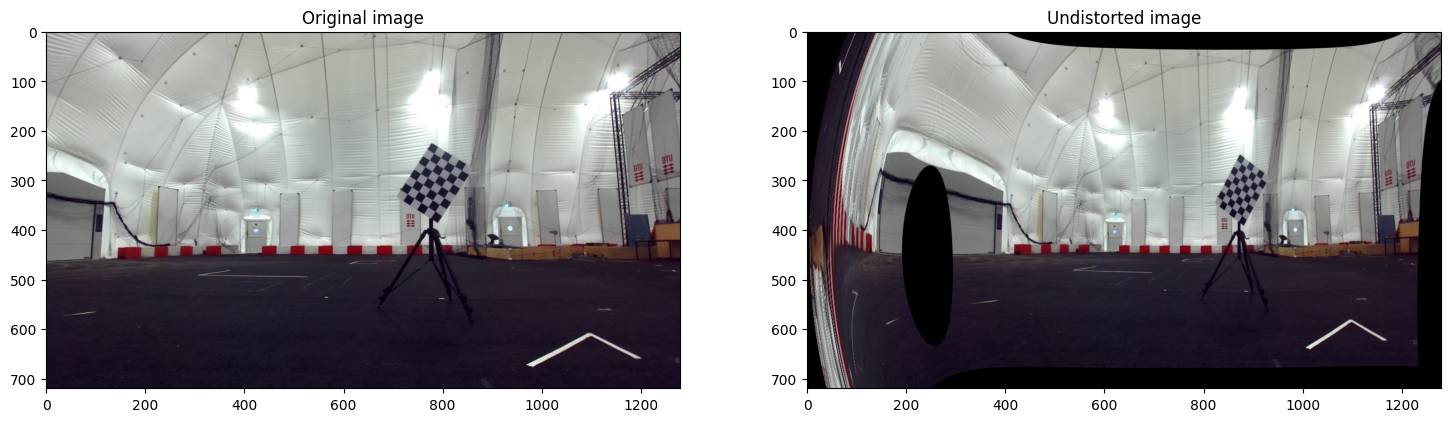

In [ ]:
# undistort
dst = cv2.undistort(img, mtx, dist, None, newcameramtx)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18,18))
ax[0].imshow(img[...,[2,1,0]])
ax[0].set_title('Original image')
ax[1].imshow(dst[...,[2,1,0]])
ax[1].set_title('Undistorted image')

Text(0.5, 1.0, 'Undistorted image')

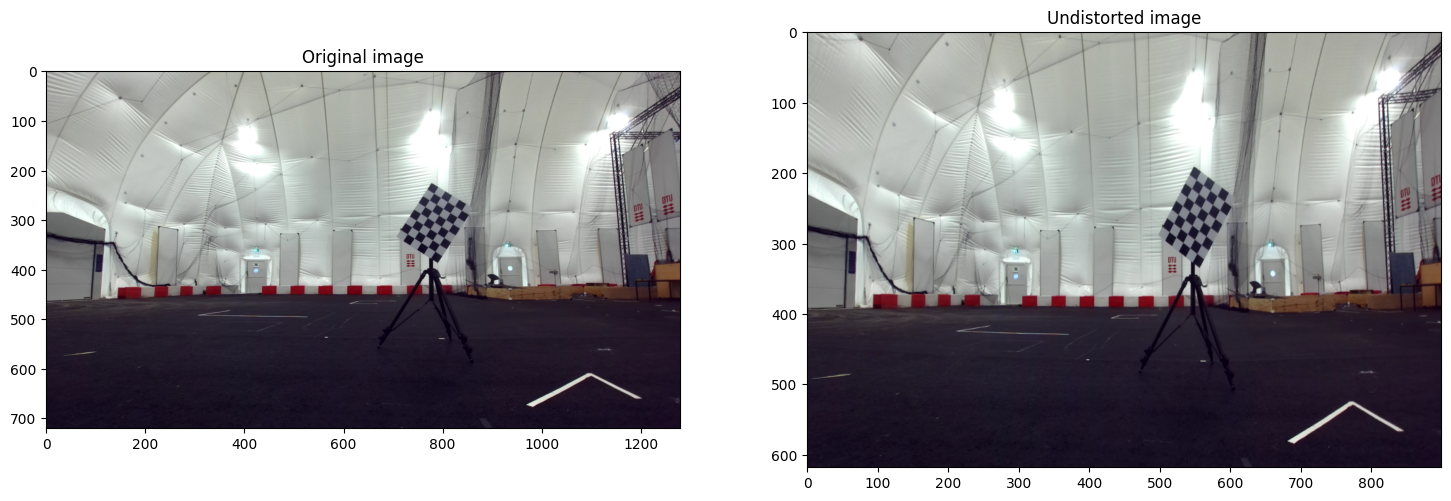

In [ ]:
# crop the image
x,y,w,h = roi
dst = dst[y:y+h, x:x+w]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18,18))
ax[0].imshow(img[...,[2,1,0]])
ax[0].set_title('Original image')
ax[1].imshow(dst[...,[2,1,0]])
ax[1].set_title('Undistorted image')